## Ejercicio 2.1
Media o mediana. Para estimar $\mu_Q$ a partir de $N$ listas se proponen dos estimadores diferentes: la media muestral $\hat{\mu}_Q$ y la mediana muestral $\tilde{\mu}_Q$. Vamos a querer medir la calidad de dichos.
### a)
Para $N = 20$ y $N = 100$, estime por simulación ($R = 2000$) el sesgo, el desvío estándar y el ECM de cada estimador. ¿Cuál conviene?

In [ ]:
# Imports
import json
import numpy as np
fro m codigo_base import *
import scipy.stats as stats
import matplotlib.pyplot as plt

# Estilo de los gráficos
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.titlesize": 11,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "legend.fontsize": 9,
})
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#52514e"

# Variables globales
rng = np.random.default_rng(4)

In [2]:
# Constantes y muestreadores que se usan en todo el bloque
n = 100
R = 2000
H_n = sum(1 / j for j in range(1, n + 1))
H2_n = sum(1 / j**2 for j in range(1, n + 1))
mu_Q = 2 * (n + 1) * H_n - 4 * n
var_Q = 7 * n**2 - 4 * (n + 1)**2 * H2_n - 2 * (n + 1) * H_n + 13 * n
mu_S = n * (n - 1) / 4
var_S = n * (n - 1) * (2 * n + 5) / 72

def muestras_Q(cantidad, n=100):
    """`cantidad` valores independientes de Q_n: corre quicksort (pivote = primero) sobre permutaciones uniformes."""
    return np.array([ALGORITMOS["quick_primero"](permutacion_aleatoria(n, rng))[1] for _ in range(cantidad)])

def muestras_S(cantidad, n=100):
    """`cantidad` valores independientes de S_n desde el modelo del ítem 1.3:
    S_n = V_1 + ... + V_n con V_j ~ U{0,...,j-1} independientes. Equivale a correr insertion sort, pero vectorizado."""
    return sum(rng.integers(0, j, size=cantidad) for j in range(1, n + 1))

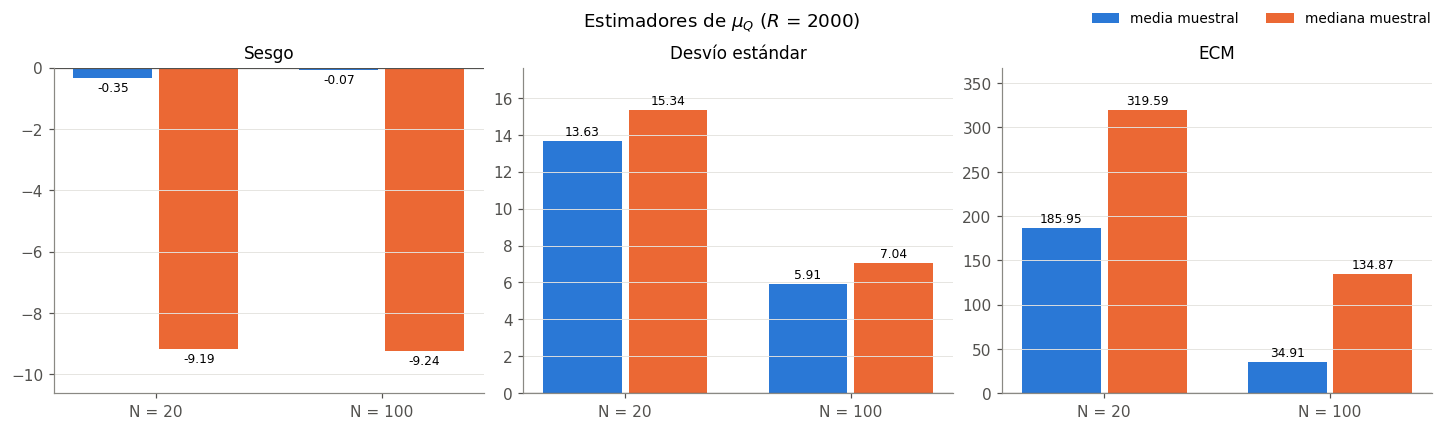

In [3]:
def evaluar_estimadores(R, N, n, algoritmo, metrica):
    estimaciones_media = []
    estimaciones_mediana = []
    if algoritmo == "quick_primero" and metrica == "comparaciones":
        H_n = sum(1/i for i in range(1, n+1))
        valor_real = 2 * (n + 1) * H_n - 4 * n
    elif algoritmo == "insertion" and metrica == "swaps":
        valor_real = n * (n - 1) / 4 

    for i in range(R):
        if algoritmo == "insertion" and metrica == "swaps":
            # Optimización: S_n sale del modelo del ítem 1.3 (validado en 1.3 d) en vez de correr insertion sort
            resultados_muestra = muestras_S(N, n)
        else:
            resultados_muestra = []
            for r in range(N):
                entrada = permutacion_aleatoria(n, rng)
                swaps, comps = ALGORITMOS[algoritmo](entrada)
            
                if metrica == "comparaciones":
                    resultados_muestra.append(comps)
                elif metrica == "swaps":
                    resultados_muestra.append(swaps)
                

        estimaciones_media.append(np.mean(resultados_muestra))
        estimaciones_mediana.append(np.median(resultados_muestra))

    # Estadísticos de la Media Muestral como estimador
    esperanza_estimador_media = np.mean(estimaciones_media)
    var_estimador_media = np.var(estimaciones_media, ddof=1)
    sesgo_media = esperanza_estimador_media - valor_real
    ecm_media = var_estimador_media + sesgo_media**2

    # Estadísticos de la Mediana Muestral como estimador
    esperanza_estimador_mediana = np.mean(estimaciones_mediana)
    var_estimador_mediana = np.var(estimaciones_mediana, ddof=1)
    sesgo_mediana = esperanza_estimador_mediana - valor_real
    ecm_mediana = var_estimador_mediana + sesgo_mediana**2

    return {
        "media": (sesgo_media, np.sqrt(var_estimador_media), ecm_media),
        "mediana": (sesgo_mediana, np.sqrt(var_estimador_mediana), ecm_mediana),
        "estimaciones": (np.array(estimaciones_media), np.array(estimaciones_mediana)),
    }

def graficar_estimadores(resultados_por_N, variable):
    """Sesgo, desvío estándar y ECM de la media y la mediana muestral, para cada N."""
    Ns = list(resultados_por_N)
    x = np.arange(len(Ns))
    ancho = 0.38
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
    for k, metrica in enumerate(["Sesgo", "Desvío estándar", "ECM"]):
        ax = axes[k]
        for j, (estimador, color) in enumerate([("media", AZUL), ("mediana", NARANJA)]):
            valores = [resultados_por_N[N][estimador][k] for N in Ns]
            barras = ax.bar(x + (j - 0.5) * ancho, valores, ancho * 0.92, color=color, label=f"{estimador} muestral")
            ax.bar_label(barras, fmt="%.2f", fontsize=8, padding=2)
        ax.axhline(0, color=GRIS, lw=0.8)
        ax.set_xticks(x, [f"N = {N}" for N in Ns])
        ax.grid(axis="x", visible=False)
        ax.margins(y=0.15)
        ax.set_title(metrica)
    fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper right", ncol=2)
    fig.suptitle(rf"Estimadores de $\mu_{variable}$ ($R$ = 2000)", fontsize=12)
    plt.show()


# N = 100
resultados_N100 = evaluar_estimadores(2000, 100, 100, "quick_primero", "comparaciones")

# N = 20
resultados_N20 = evaluar_estimadores(2000, 20, 100, "quick_primero", "comparaciones")

resultados_Q = {20: resultados_N20, 100: resultados_N100}
graficar_estimadores(resultados_Q, "Q")


i) ¿Cuál conviene?

El estimador que más conviene es el que tiene menor ECM. Para ambos casos, N = 100 o N = 20 es la media muestral como estimador.


### b) 
Repita para $\mu_S$ con $\hat{\mu}_S$ y $\tilde{\mu}_S$. ¿La razón por la que un estimador resulta peor que el otro es la misma para $S_{100}$ que para $Q_{100}$? ¿Qué pasa con el sesgo de $\tilde{\mu}_Q$ cuando $N$ crece?
¿Qué parámetro estima en realidad la mediana muestral?

# (???)
Preguntan que pasa con el sesgo de $\tilde{\mu}_Q$ cuando $N$ crece. $Q$ lo mirabamos en el inciso anterior, y practicamente no cambia, se estanca en un valor negativo. En este inciso pasa de negativo a positivo, pero se reduce en modulo, mostrando una tendencia a acercarse en modulo al 0 (?


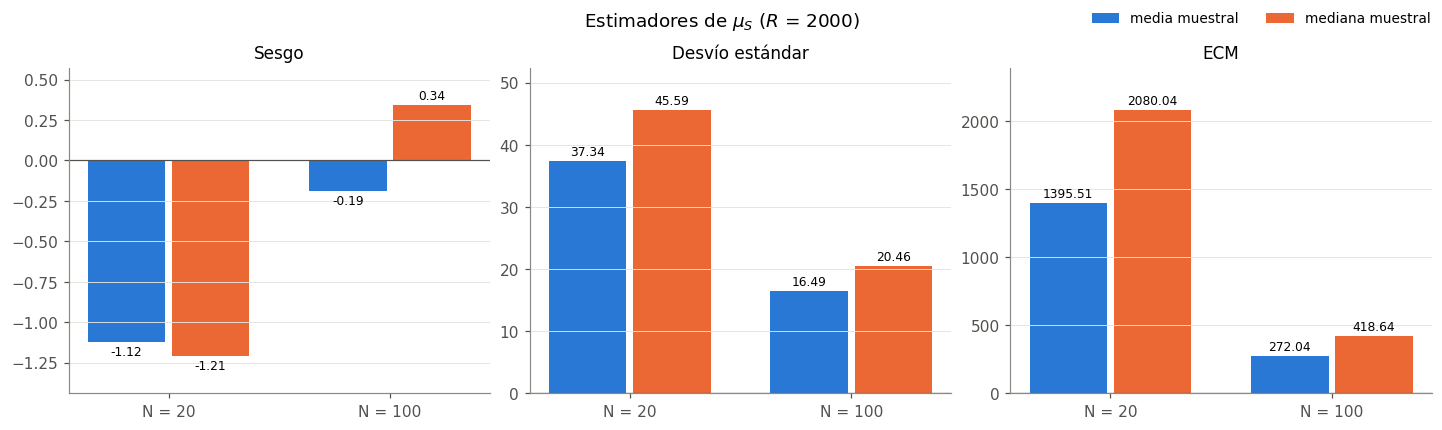

In [4]:
# N = 100
resultados_N100 = evaluar_estimadores(2000, 100, 100, "insertion", "swaps")

# N = 20
resultados_N20 = evaluar_estimadores(2000, 20, 100, "insertion", "swaps")

resultados_S = {20: resultados_N20, 100: resultados_N100}
graficar_estimadores(resultados_S, "S")


#### i) ¿La razón por la que un estimador resulta peor que el otro es la misma para $S_{100}$ que para $Q_{100}$? 

No. 

En ambos casos el estimador que resulta peor es la mediana, pero por motivos distintos. 
Para $Q_{100}$, la mediana pierde por culpa del sesgo:
La diferencia de los sesgos al cuadrado es de $9.24^2 ≈ 85$ mientras que la de varianzas es $7.04^2 − 5.91^2 ≈ 14.6$

Para $S_{100}$ la mediana pierde por culpa de la varianza: 
La diferencia en los sesgos al cuadrado es ínfima ($0.34^2 − 0.19^2 ≈ 0.08$) pero la diferencia de sus varianzas es de $20.46^2 − 16.49^2 ≈ 146.5$.

#### ii) ¿Qué pasa con el sesgo de $\tilde{\mu}_Q$ cuando $N$ crece?

El sesgo pasa de $-9.1878$ con $N=20$ a $-9.2380$ con $N=100$. Es decir que se mantiene subestimando por $\sim 9$ a la media.


El estimador $\tilde{\mu}_Q$ converge a la mediana poblacional de Q, por eso es sesgado para estimar la media.


#### iii) ¿Qué parámetro estima en realidad la mediana muestral?

El parámetro que estima es la mediana poblacional de $Q$.

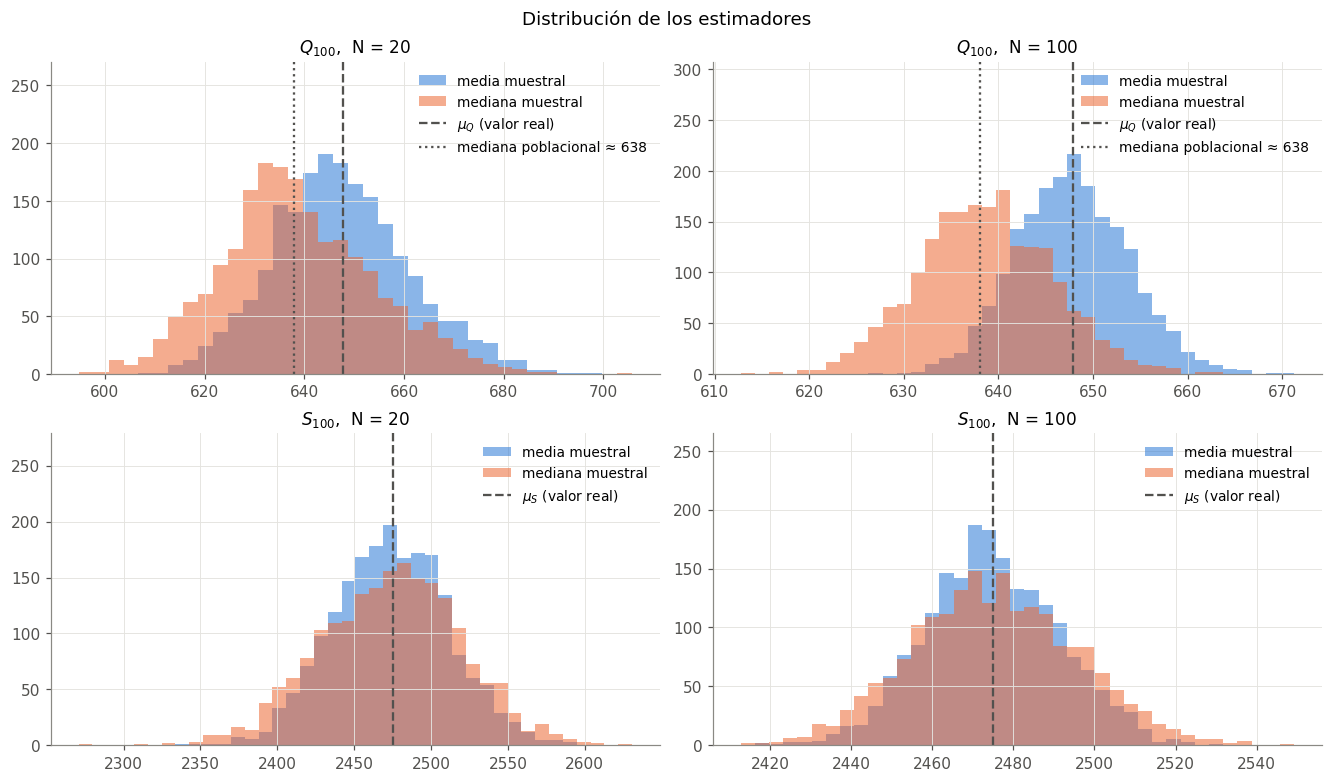

In [5]:
# Poblaciones grandes (10^5 valores de cada variable): acá para la mediana poblacional, y en c) para γ_S y γ_Q
Q_grande = muestras_Q(100_000)
S_grande = muestras_S(100_000)
mediana_pob_Q = np.median(Q_grande)

# Distribución de los 2000 valores de cada estimador (mismas simulaciones de a) y b))
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
for fila, (variable, resultados, mu) in enumerate([("Q", resultados_Q, mu_Q), ("S", resultados_S, mu_S)]):
    for col, N in enumerate([20, 100]):
        ax = axes[fila, col]
        medias, medianas = resultados[N]["estimaciones"]
        # bins de ancho múltiplo de 0.5 (las medianas valen enteros o medios enteros)
        todos = np.concatenate([medias, medianas])
        ancho = np.ceil((todos.max() - todos.min()) / 40 * 2) / 2
        bins = np.arange(np.floor(todos.min()) - 0.25, todos.max() + ancho, ancho)
        ax.hist(medias, bins=bins, color=AZUL, alpha=0.55, label="media muestral")
        ax.hist(medianas, bins=bins, color=NARANJA, alpha=0.55, label="mediana muestral")
        ax.axvline(mu, color=GRIS, ls="--", lw=1.5, label=rf"$\mu_{variable}$ (valor real)")
        if variable == "Q":
            ax.axvline(mediana_pob_Q, color=GRIS, ls=":", lw=1.5, label=f"mediana poblacional ≈ {mediana_pob_Q:.0f}")
        ax.set_title(rf"${variable}_{{100}}$,  N = {N}")
        ax.set_ylim(top=ax.get_ylim()[1] * 1.35)
        ax.legend(loc="upper right")
fig.suptitle("Distribución de los estimadores", fontsize=12)
plt.show()


En $Q_{100}$ el histograma de la mediana (naranja) está corrido a la izquierda de $\mu_Q$: se centra en la mediana poblacional, no en la media. En $S_{100}$ los dos histogramas están centrados en $\mu_S$, pero el de la mediana es más ancho.


### c) 
Estime $\gamma_S$ y $\gamma_Q$ con una simulación muy grande (por ejemplo, $10^5$ listas; para $S_{100}$ puede usar la simulación desde el modelo del ítem 1.3). Luego estudie el estimador $\hat{\gamma}$ con $N = 20,50,200$: estime su sesgo y su desvío para cada variable. ¿Qué tan preciso es el valor de $\hat{\mu}_Q$ que calculó en el ítem 1.2?

γ_S ≈ -0.0026   γ_Q ≈ 0.9618   (10^5 listas)



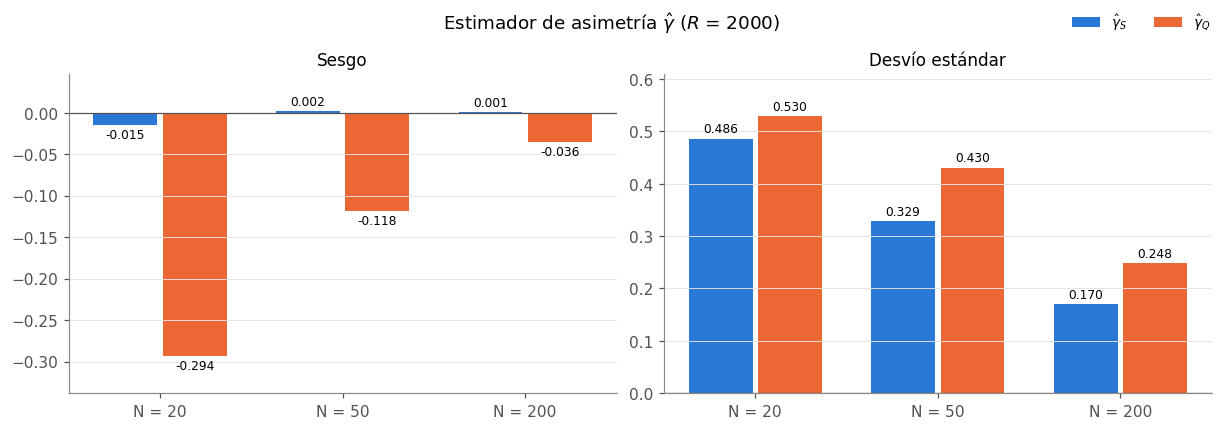

In [6]:

asimetria_S_N100000 = stats.skew(S_grande)
asimetria_Q_N100000 = stats.skew(Q_grande)
print(f"γ_S ≈ {asimetria_S_N100000:.4f}   γ_Q ≈ {asimetria_Q_N100000:.4f}   (10^5 listas)\n")

def evaluar_estimador_asimetria(N, asimetria_S_real, asimetria_Q_real, R):
    # R muestras nuevas de tamaño N de cada variable: cada fila da una estimación γ̂
    estimaciones_S = stats.skew(muestras_S(R * N).reshape(R, N), axis=1)
    estimaciones_Q = stats.skew(muestras_Q(R * N).reshape(R, N), axis=1)

    # Estadísticos del estimador para S (Insertion)
    sesgo_S = np.mean(estimaciones_S) - asimetria_S_real
    desvio_S = np.std(estimaciones_S, ddof=1)

    # Estadísticos del estimador para Q (QuickSort)
    sesgo_Q = np.mean(estimaciones_Q) - asimetria_Q_real
    desvio_Q = np.std(estimaciones_Q, ddof=1)

    return sesgo_S, desvio_S, sesgo_Q, desvio_Q, estimaciones_S, estimaciones_Q

# resultados_gamma[N] = (sesgo_S, desvio_S, sesgo_Q, desvio_Q, estimaciones_S, estimaciones_Q)
resultados_gamma = {}
for N in [200, 50, 20]:
    resultados_gamma[N] = evaluar_estimador_asimetria(N, asimetria_S_N100000, asimetria_Q_N100000, R)

# Sesgo y desvío de γ̂ para cada N
Ns_c = [20, 50, 200]
x = np.arange(len(Ns_c))
ancho = 0.38
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for k, metrica in enumerate(["Sesgo", "Desvío estándar"]):
    ax = axes[k]
    for j, (variable, color) in enumerate([("S", AZUL), ("Q", NARANJA)]):
        valores = [resultados_gamma[N][2 * j + k] for N in Ns_c]
        barras = ax.bar(x + (j - 0.5) * ancho, valores, ancho * 0.92, color=color, label=rf"$\hat\gamma_{variable}$")
        ax.bar_label(barras, fmt="%.3f", fontsize=8, padding=2)
    ax.axhline(0, color=GRIS, lw=0.8)
    ax.set_xticks(x, [f"N = {N}" for N in Ns_c])
    ax.grid(axis="x", visible=False)
    ax.margins(y=0.15)
    ax.set_title(metrica)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper right", ncol=2)
fig.suptitle(rf"Estimador de asimetría $\hat\gamma$ ($R$ = {R})", fontsize=12)
plt.show()


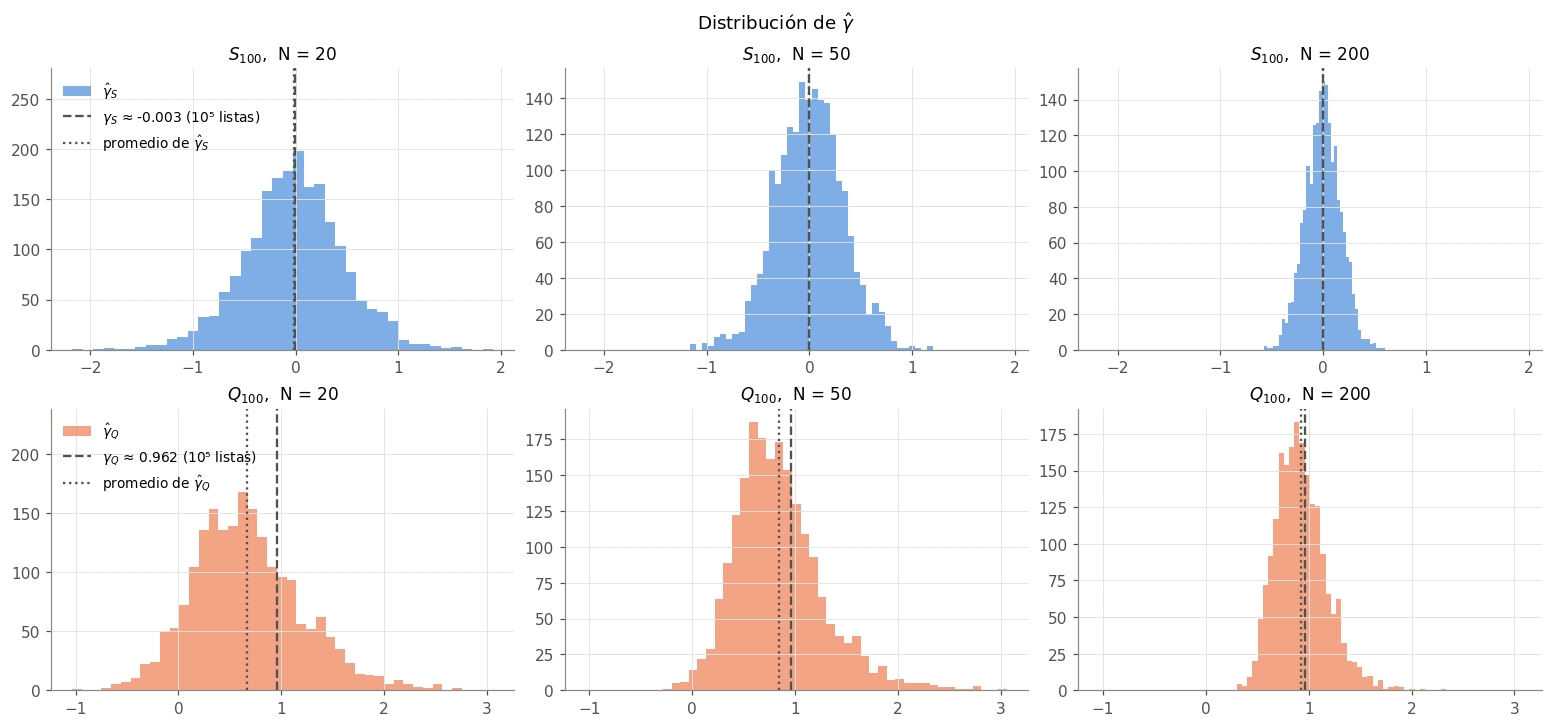

In [7]:
# Distribución de los R valores de γ̂ para cada N
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5), constrained_layout=True, sharex="row")
for fila, (variable, idx, gamma_real, color) in enumerate([("S", 4, asimetria_S_N100000, AZUL),
                                                           ("Q", 5, asimetria_Q_N100000, NARANJA)]):
    for col, N in enumerate(Ns_c):
        ax = axes[fila, col]
        estimaciones = resultados_gamma[N][idx]
        ax.hist(estimaciones, bins=40, color=color, alpha=0.6, label=rf"$\hat\gamma_{variable}$")
        ax.axvline(gamma_real, color=GRIS, ls="--", lw=1.5, label=rf"$\gamma_{variable}$ ≈ {gamma_real:.3f} (10⁵ listas)")
        ax.axvline(np.mean(estimaciones), color=GRIS, ls=":", lw=1.5, label=rf"promedio de $\hat\gamma_{variable}$")
        ax.set_title(rf"${variable}_{{100}}$,  N = {N}")
        if col == 0:
            ax.set_ylim(top=ax.get_ylim()[1] * 1.35)
            ax.legend(loc="upper left")
fig.suptitle(r"Distribución de $\hat\gamma$", fontsize=12)
plt.show()


i) ¿Qué tan preciso es el valor de $\hat{\mu}_Q$ que calculó en el ítem 1.2?

Es bastante preciso, ya que como vemos en la simulacion con N = 200, el sesgo y el desvío son muy chicos (más cercanos a 0 que a 1). La tendencia de ambos también es bajar a medida que el N crece. Por eso, usando N = 2000 en el item 1.2 el sesgo y varianza deben ser aún menores para experimentos de esa magnitud de listas.

## Ejercicio 2.2
Distribución de la media muestral. Sea $\hat{\mu}_Q$ la media de las comparaciones de quicksort sobre $N$ listas independientes.
### a)
Muestre que $\mathrm{Var}(\hat{\mu}_Q) = \sigma_Q^2/N$ y que $\gamma_{\hat{\mu}_Q} = \gamma_Q/\sqrt{N}$. (Ayuda: considere $\hat{\mu}_Q - \mu_Q = \frac{1}{N}\sum_{i=1}^N (Q^{(i)} - \mu_Q)$ y use $D_i = Q^{(i)} - \mu_Q$, desarrolle el cubo y piense qué términos tienen esperanza nula.)

#### $\mathrm{Var}(\hat{\mu}_Q) = \sigma_Q^2/N$

Partimos de la ayuda:
$$\hat{\mu}_Q - \mu_Q = \frac{1}{N}\sum_{i=1}^N D_i, \qquad D_i = Q^{(i)} - \mu_Q$$

Aplicamos varianza de ambos lados.

**Lado izquierdo:** $\mu_Q$ es una constante, y restarle una constante a una variable aleatoria no cambia su dispersión:
$$\mathrm{Var}(\hat{\mu}_Q - \mu_Q) = \mathrm{Var}(\hat{\mu}_Q)$$

**Lado derecho:** como las $D_i$ son independientes, la varianza de la suma es la suma de las varianzas, y además $\mathrm{Var}(D_i) = \mathrm{Var}(Q^{(i)}) = \sigma_Q^2$:
$$\mathrm{Var}\left(\frac{1}{N}\sum_{i=1}^N D_i\right) = \frac{1}{N^2}\sum_{i=1}^N \mathrm{Var}(D_i) = \frac{1}{N^2}\, N\sigma_Q^2 = \frac{\sigma_Q^2}{N}$$

Igualando ambos lados:
$$\boxed{\mathrm{Var}(\hat{\mu}_Q) = \frac{\sigma_Q^2}{N}}$$


#### $\gamma_{\hat{\mu}_Q} = \gamma_Q/\sqrt{N}$

La definición de coeficiente de asimetría es que 
$$ \gamma_X = \frac{E[(X-\mu)^3]}{\sigma^3} $$

Donde tenemos que en el caso de $\gamma_{\hat{\mu}_Q}$:

$$ X = \hat{\mu}_Q \qquad \mu = E[\hat{\mu}_Q] \qquad \sigma = \sqrt{Var(\hat{\mu}_Q)} $$

Y en el caso de $\gamma_{Q}$:

$$ X = Q \qquad \mu = E[Q] \qquad \sigma = \sqrt{Var(Q)} $$

Entonces,

$$ \gamma_{\hat{\mu}_Q} = \frac{E[(\hat{\mu}_Q-E[\hat{\mu}_Q])^3]}{\sqrt{Var(\hat{\mu}_Q)}^3} \qquad \gamma_Q = \frac{E[(Q-E[Q])^3]}{\sqrt{Var(Q)}^3} $$

Buscamos descomponer $E[\hat{\mu}_Q]$ y $Var(\hat{\mu}_Q)$

$$ E[\hat{\mu}_Q] = E[\frac{1}{N}\sum_{i=1}^N D_i] = \frac{1}{N}\sum_{i=1}^N E[D_i] = \frac{1}{N} N \mu_Q = E[Q] $$

$$ Var(\hat{\mu}_Q) = Var(\frac{1}{N}\sum_{i=1}^N D_i) = \frac{1}{N^2}\sum_{i=1}^N Var(D_i) = \frac{1}{N^2} N \sigma^2_Q = \frac{\sigma^2_Q}{N} $$

Entonces reemplazamos:

$$ \gamma_{\hat{\mu}_Q} = \frac{E[(\hat{\mu}_Q-E[Q])^3]}{\sqrt{\frac{\sigma^2_Q}{N}}^3} = \frac{E[(\hat{\mu}_Q-E[Q])^3]}{(\frac{\sigma_Q}{\sqrt{N}})^3} $$

El término $\hat{\mu}_Q-E[Q]$, lo podemos descomponer como $ \frac{1}{N}\sum_{i=1}^N D_i$

Luego desarrollamos $E[(\hat{\mu}_Q-E[Q])^3] = E[(\frac{1}{N}\sum_{i=1}^N D_i)^3] $:

$$ E[\frac{1}{N}(\sum_{i=1}^N D_i)^3] = \frac{1}{N^3} E[(\sum_{i=1}^N D_i)^3] = \frac{1}{N^3} \sum_{i=1}^N \sum_{j=1}^N \sum_{k=1}^N E[D_i D_j D_k]$$

Como las $D_i$ son independientes, solo sobreviven a la multiplicación cuando todos los términos son iguales, o sea que nos queda que:

$$ E[D_i^3] = E[(Q − μ_Q)^3] = γ_Q σ_Q^3 $$

Y como hay N términos asi (uno por cada $i$) queda que:

$$ E\left[(\hat{\mu}_Q-E[Q])^3\right] = \frac{1}{N^3}\cdot N\cdot \gamma_Q\,\sigma_Q^3 = \frac{\gamma_Q\,\sigma_Q^3}{N^2} $$

Por último, usamos esto para reemplazar en $\gamma_{\hat{\mu}_Q}$:

$$ \gamma_{\hat{\mu}_Q} = \frac{E\left[(\hat{\mu}_Q-E[Q])^3\right]}{\left(\frac{\sigma_Q}{\sqrt{N}}\right)^3}
= \frac{\gamma_Q\,\sigma_Q^3 / N^2}{\sigma_Q^3 / N^{3/2}}
= \frac{\gamma_Q}{\sqrt{N}} $$

O sea que,

$$ \boxed{\gamma_{\hat{\mu}_Q} = \gamma_Q/\sqrt{N}} $$

### b)
Verifíquelo por simulación para $N = 1, 4, 9, 25$ con $R = 2000$ valores de $\hat{\mu}_Q$: histogramas, gráficos cuantil-cuantil contra la normal, varianza y asimetría comparadas con los valores teóricos.

<>:52: SyntaxWarning: invalid escape sequence '\h'
<>:52: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_9627/3563982823.py:52: SyntaxWarning: invalid escape sequence '\h'
  fig.suptitle("Distribución de la media muestral de Quicksort ($\hat{\mu}_Q$)", fontsize=14)


--- N = 1 ---
Varianza  | Empírica:  3673.67  |  Teórica:  3538.27
Asimetría | Empírica:   0.9562  |  Teórica:   0.9618

--- N = 4 ---
Varianza  | Empírica:   866.94  |  Teórica:   884.57
Asimetría | Empírica:   0.4324  |  Teórica:   0.4809

--- N = 9 ---
Varianza  | Empírica:   374.42  |  Teórica:   393.14
Asimetría | Empírica:   0.2964  |  Teórica:   0.3206

--- N = 25 ---
Varianza  | Empírica:   140.69  |  Teórica:   141.53
Asimetría | Empírica:   0.1970  |  Teórica:   0.1924



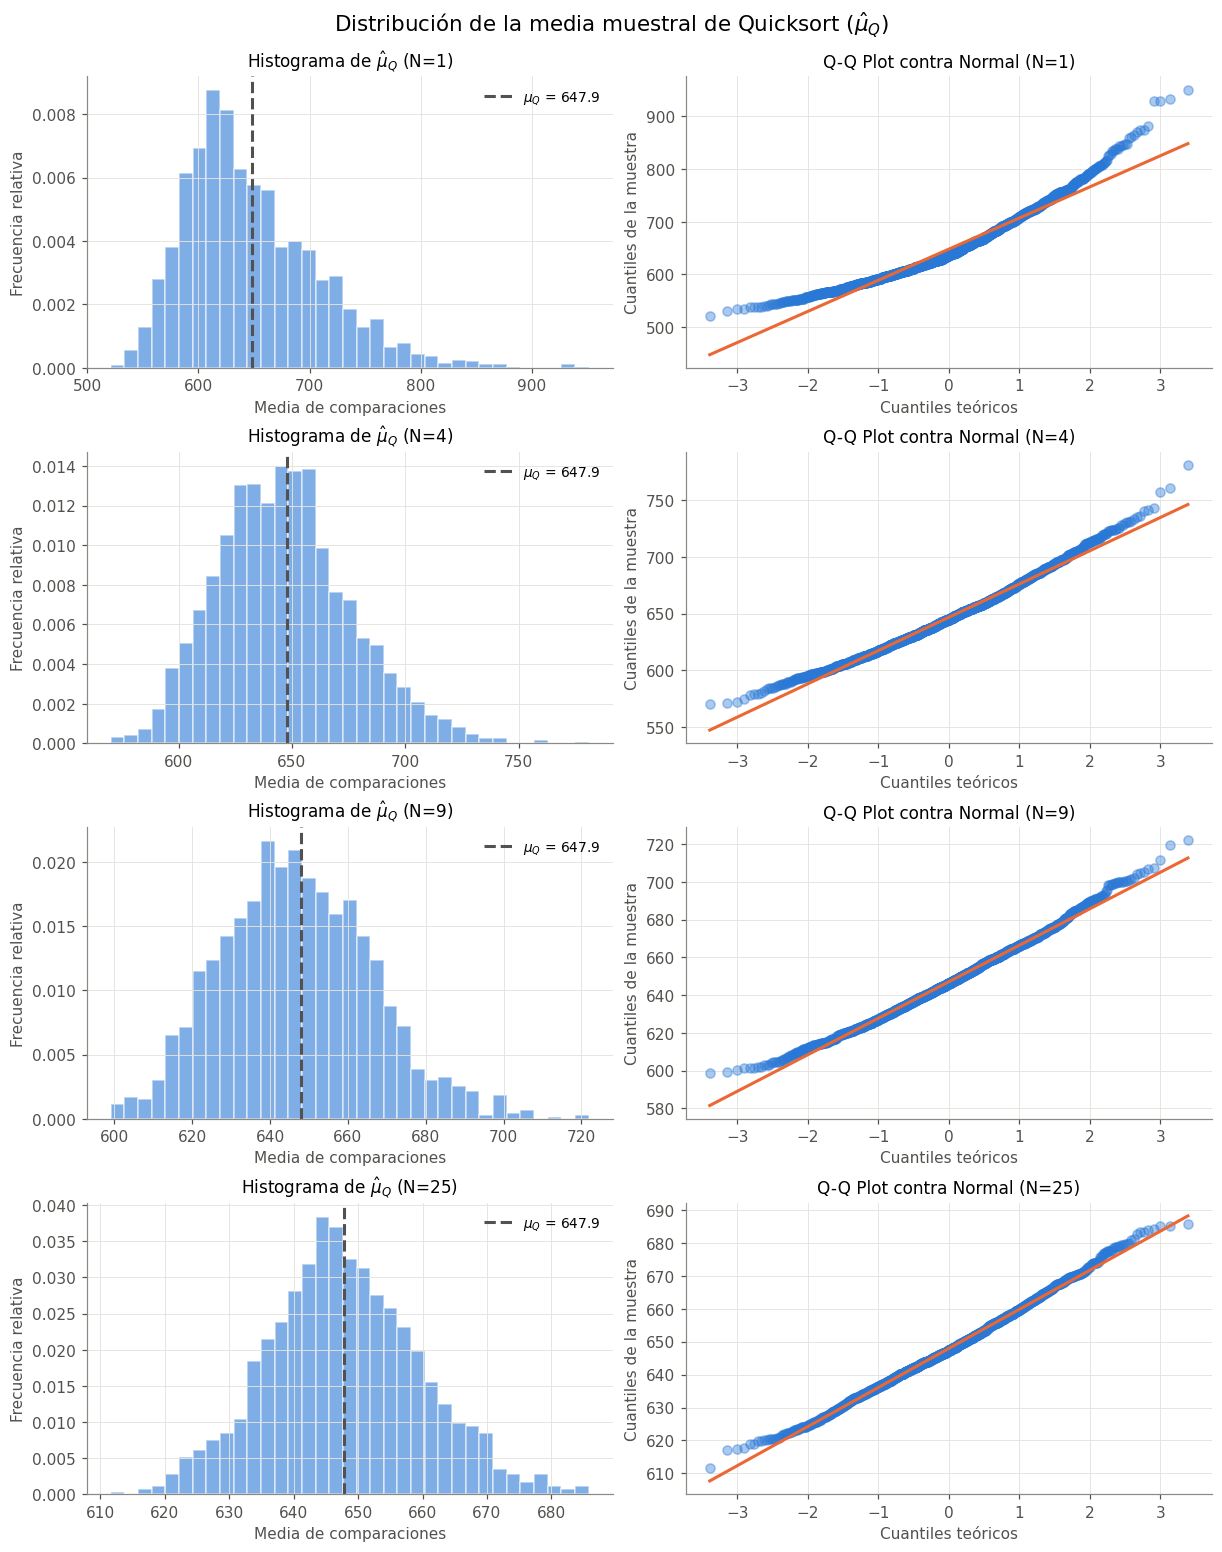

In [8]:
resultados_22b = {}
Ns_22b = [1, 4, 9, 25]

for N in Ns_22b:
    # Simulamos R * N ejecuciones y agrupamos en R filas de tamaño N
    muestras = muestras_Q(R * N, n=100).reshape(R, N)
    
    # Calculamos la media muestral por cada fila
    medias_muestrales = np.mean(muestras, axis=1)
    resultados_22b[N] = medias_muestrales
    
    # Cálculos empíricos
    var_emp = np.var(medias_muestrales, ddof=1)
    asim_emp = stats.skew(medias_muestrales)
    
    # Cálculos teóricos (usando las propiedades del inciso a)
    var_teo = var_Q / N
    asim_teo = asimetria_Q_N100000 / np.sqrt(N)
    
    print(f"--- N = {N} ---")
    print(f"Varianza  | Empírica: {var_emp:8.2f}  |  Teórica: {var_teo:8.2f}")
    print(f"Asimetría | Empírica: {asim_emp:8.4f}  |  Teórica: {asim_teo:8.4f}\n")

# Gráficos

fig, axes = plt.subplots(len(Ns_22b), 2, figsize=(11, 14), constrained_layout=True)

for i, N in enumerate(Ns_22b):
    medias = resultados_22b[N]
    
    # Histograma
    ax_hist = axes[i, 0]
    ax_hist.hist(medias, bins=35, density=True, color=AZUL, alpha=0.6, edgecolor='white')
    ax_hist.axvline(mu_Q, color=GRIS, ls="--", lw=2, label=rf"$\mu_Q$ = {mu_Q:.1f}")
    ax_hist.set_title(rf"Histograma de $\hat{{\mu}}_Q$ (N={N})")
    ax_hist.set_xlabel("Media de comparaciones")
    ax_hist.set_ylabel("Frecuencia relativa")
    ax_hist.legend()
    
    # Grafico cuantil cuantil
    ax_qq = axes[i, 1]
    stats.probplot(medias, dist="norm", plot=ax_qq)
    ax_qq.set_title(f"Q-Q Plot contra Normal (N={N})")
    ax_qq.set_xlabel("Cuantiles teóricos")
    ax_qq.set_ylabel("Cuantiles de la muestra")
    ax_qq.get_lines()[0].set_markerfacecolor(AZUL)
    ax_qq.get_lines()[0].set_markeredgecolor(AZUL)
    ax_qq.get_lines()[0].set_alpha(0.4)
    ax_qq.get_lines()[1].set_color(NARANJA)
    ax_qq.get_lines()[1].set_linewidth(2)

fig.suptitle("Distribución de la media muestral de Quicksort ($\hat{\mu}_Q$)", fontsize=14)
plt.show()

### c)
Relacione con el teorema central del límite. ¿A partir de qué $N$ le parece razonable aproximar la distribución de $\hat{\mu}_Q$ por una normal?

La asimetría original de las comparaciones de Quicksort es aproximadamente 0.96 ($N=1$). Como la asimetría de la media muestral decae a un ritmo de $\frac{1}{\sqrt{N}}$(inciso a), para $N=9$ la asimetría se reduce a la tercera parte ($0.96/3=0.32$). Con una asimetría de 0.32 el histograma se ve, a ojo, acampanado y los puntos centrales del grafico cuantil cuantil se alinean bastante con la recta teórica.

Para $N=25$, la asimetría baja a la quinta parte (0.96/5≈0.19). Con tan poca asimetría, la convergencia tanto visual como numérica es casi total, ajustándose mucho incluso en las colas del grafico cuantil cuantil.

$N=9$ podría ser razonable para aproximar la distribución a una normal. Si queremos bastante más confianza podemos usar $N=25$

## Ejercicio 2.3. 
Intervalos de confianza.

### a) 

Construya intervalos de confianza de nivel 0,95 para $\mu_S$ y para $\mu_Q$ a partir de $N$ listas, de dos formas: con la varianza teórica conocida (intervalo $z$) y con la varianza muestral (intervalo $t$).

Interalos de confianza de nivel 0,95 ($\alpha = 0,05$):

Intervalo $z$:
Usamos la varianza teórica $\sigma^2$ conocida para cada caso.

$I_{z_Q} = \left [ \hat{\mu}_Q - z_{0,975} \cdot \frac{\sigma_Q}{\sqrt{N}}, \hat{\mu}_Q + z_{0,975} \cdot \frac{\sigma_Q}{\sqrt{N}} \right ]$

$I_{z_S} = \left [ \hat{\mu}_S - z_{0,975} \cdot \frac{\sigma_S}{\sqrt{N}}, \hat{\mu}_S + z_{0,975} \cdot \frac{\sigma_S}{\sqrt{N}} \right ]$

Donde $\sigma_Q$ y $\sigma_S$ son las raices cuadradas de las constantes calculadas al principio var_Q y var_S respectivamente. 

Intervalo $t$:
Usamos la varianza muestral $S^2$ para cada caso.

$I_{t_Q} = \left [ \hat{\mu}_Q - t_{0,975, N-1} \cdot \frac{S^2_Q}{\sqrt{N}}, \hat{\mu}_Q + t_{0,975, N-1} \cdot \frac{S^2_Q}{\sqrt{N}} \right ]$

$I_{t_S} = \left [ \hat{\mu}_S - t_{0,975, N-1} \cdot \frac{S^2_S}{\sqrt{N}}, \hat{\mu}_S + t_{0,975, N-1} \cdot \frac{S^2_S}{\sqrt{N}} \right ]$




### b) 

Repita la construcción $R = 2000$ veces para $N = 5,10,30,100$ y estime la cobertura, es decir, la proporción de intervalos que contienen el valor verdadero. Informe además por separado la proporción de intervalos que quedan enteramente por encima y enteramente por debajo del valor verdadero.

In [9]:
Ns = [5, 10, 30, 100]
R = 2000
alpha = 0.05
z_crit = stats.norm.ppf(1 - alpha/2) # Aprox 1.96

def evaluar_intervalos(generador_muestras, mu_real, var_real, N, R=2000):
    # Simulamos R muestras de tamaño N
    muestras = generador_muestras(R * N).reshape(R, N)
    
    # Estimadores muestrales para cada una de las R filas
    medias = np.mean(muestras, axis=1)
    desvios = np.std(muestras, ddof=1, axis=1)
    
    # Intervalo z (varianza poblacional conocida)
    margen_z = z_crit * np.sqrt(var_real / N)
    inf_z, sup_z = medias - margen_z, medias + margen_z
    
    # Intervalo t (varianza muestral)
    t_crit = stats.t.ppf(1 - alpha/2, df=N-1)
    margen_t = t_crit * (desvios / np.sqrt(N))
    inf_t, sup_t = medias - margen_t, medias + margen_t

    res_z = cobertura(inf_z, sup_z, mu_real)
    res_t = cobertura(inf_t, sup_t, mu_real)
    return res_z, res_t

# Función para calcular la proporción de intervalos que contienen el valor verdadero
def cobertura(inf, sup, mu_real):
    adentro = np.mean((inf <= mu_real) & (mu_real <= sup))
    # Intervalo entero por encima del valor verdadero (límite inferior > mu)
    arriba = np.mean(inf > mu_real)
    # Intervalo entero por debajo del valor verdadero (límite superior < mu)
    abajo = np.mean(sup < mu_real)
    return adentro, arriba, abajo

def imprimir_resultados(variable, mu_real, var_real, func_muestras):
    print(f"\n{'='*40}\nResultados para {variable}_{{100}} (mu_real={mu_real:.2f})\n{'='*40}")
    for N in Ns:
        (cob_z, arr_z, aba_z), (cob_t, arr_t, aba_t) = evaluar_intervalos(func_muestras, mu_real, var_real, N, R)
        
        print(f"--- N = {N:3d} ---")
        print(f"  Int. Z -> Cobertura: {cob_z:.4f} | Por encima: {arr_z:.4f} | Por debajo: {aba_z:.4f}")
        print(f"  Int. T -> Cobertura: {cob_t:.4f} | Por encima: {arr_t:.4f} | Por debajo: {aba_t:.4f}")

# Ejecutamos para S (Insertion Sort) y Q (Quicksort)
imprimir_resultados("S", mu_S, var_S, muestras_S)
imprimir_resultados("Q", mu_Q, var_Q, muestras_Q)


Resultados para S_{100} (mu_real=2475.00)
--- N =   5 ---
  Int. Z -> Cobertura: 0.9385 | Por encima: 0.0300 | Por debajo: 0.0315
  Int. T -> Cobertura: 0.9355 | Por encima: 0.0290 | Por debajo: 0.0355
--- N =  10 ---
  Int. Z -> Cobertura: 0.9580 | Por encima: 0.0220 | Por debajo: 0.0200
  Int. T -> Cobertura: 0.9560 | Por encima: 0.0240 | Por debajo: 0.0200
--- N =  30 ---
  Int. Z -> Cobertura: 0.9515 | Por encima: 0.0245 | Por debajo: 0.0240
  Int. T -> Cobertura: 0.9535 | Por encima: 0.0240 | Por debajo: 0.0225
--- N = 100 ---
  Int. Z -> Cobertura: 0.9485 | Por encima: 0.0300 | Por debajo: 0.0215
  Int. T -> Cobertura: 0.9450 | Por encima: 0.0315 | Por debajo: 0.0235

Resultados para Q_{100} (mu_real=647.85)
--- N =   5 ---
  Int. Z -> Cobertura: 0.9395 | Por encima: 0.0385 | Por debajo: 0.0220
  Int. T -> Cobertura: 0.9210 | Por encima: 0.0100 | Por debajo: 0.0690
--- N =  10 ---
  Int. Z -> Cobertura: 0.9520 | Por encima: 0.0310 | Por debajo: 0.0170
  Int. T -> Cobertura: 0.93

### c) 

¿La cobertura es la nominal? ¿Por qué los fallos no se reparten por igual entre los dos lados para $Q_{100}$ y sí para $S_{100}$? Relacione con el ítem 2.2.